In [5]:
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

#create data
x_soc = np.array([53.3,60.2,63.2,62.1,68.6, 56.1, 57.8, 64.1, 57.1, 55.8])
y_soc = np.array([0.02,0.1,0.18,-0.03,0.15, -0.09, 0.21, -0.05, 0.14, -0.12])

x_mockSFC = np.array([56.0,51.1,63.4,60.1,64.35, 58.4,  60.3, 55.9,  58.4, 52.7])
y_mockSFC = np.array([0,0.21,0.14,-0.1,0.0182, 0.095, -0.05, -0.131, 0.17, 0.05])

x = np.subtract(x_mockSFC, x_soc)
y = np.subtract(y_mockSFC, y_soc)
flag = ['n' for i in range(len(x))]
#y = np.absolute(y)

print(x)
print(y)

print(np.corrcoef(x,y))
print(np.mean(y))

[ 2.7  -9.1   0.2  -2.   -4.25  2.3   2.5  -8.2   1.3  -3.1 ]
[-0.02    0.11   -0.04   -0.07   -0.1318  0.185  -0.26   -0.081   0.03
  0.17  ]
[[ 1.         -0.11040629]
 [-0.11040629  1.        ]]
-0.010780000000000007


In [6]:
x2_soc = np.array([53.3,60.2,63.2,62.1,68.6, 56.1, 57.8, 64.1, 57.1, 55.8]) #decoding
y2_soc = np.array([0.02,0.1,0.18,-0.03,0.15, -0.09, 0.21, -0.05, 0.14, -0.12]) #behavior

x2_mockExt = np.array([55.3,60.4,64.7,57.4,65.6, 60.1, 59.8, 65.1,  56.4, 52.7]) #decoding
y2_mockExt = np.array([0.08,-0.02,0.1,0.1,-0.07, 0.14, -0.15, -0.18, 0.08, -0.1]) #behavior

x2 = np.subtract(x2_mockExt, x2_soc)
y2 = np.subtract(y2_mockExt, y2_soc)
flag_2 = ['y' for i in range(len(x2))]
#y = np.absolute(y)

print(x2)
print(y2)
print('mean:')
print(np.mean(x2))
print(np.mean(y2))

print('Pearson\'s correlation:')
print(np.corrcoef(x2,y2))

[ 2.   0.2  1.5 -4.7 -3.   4.   2.   1.  -0.7 -3.1]
[ 0.06 -0.12 -0.08  0.13 -0.22  0.23 -0.36 -0.13 -0.06  0.02]
mean:
-0.08000000000000043
-0.053000000000000005
Pearson's correlation:
[[1.        0.0076561]
 [0.0076561 1.       ]]


In [7]:
x_df = list(x)
x_df.extend(x2)
y_df = list(y)
y_df.extend(y2)
flag.extend(flag_2)

dataframe = pd.DataFrame(list(zip(x_df, y_df, flag)),columns=['x','y','r3r4'])

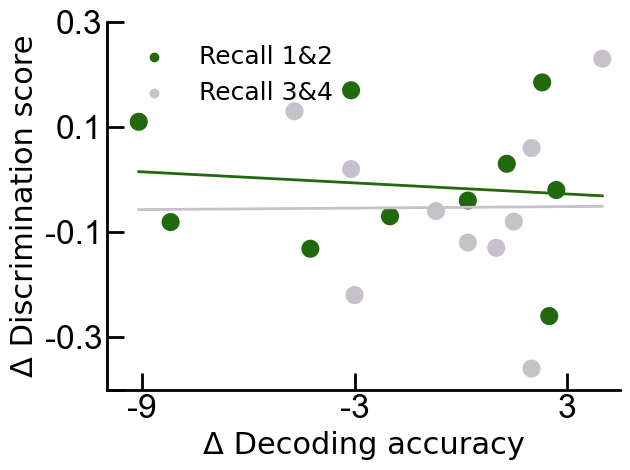

In [14]:
colors = ["#22690d","#c7c1c9"]

fig, ax = plt.subplots()  # create figure and axes

# plot on ax (Axes) object
sns.scatterplot(data=dataframe, x='x', y='y',hue='r3r4',palette=colors,s=200)

#mfc='none'
#obtain m (slope) and b(intercept) of linear regression line
m, b = np.polyfit(x, y, 1)
m2, b2 = np.polyfit(x2,y2,1)

#add linear regression line to scatterplot 
#ax.plot(x, m*x+b, color='#144e96')
l_reg_line = np.array([min(x.min(),x2.min()),max(x.max(),x2.max())])
ax.plot(l_reg_line, m*l_reg_line+b, color=colors[0], linewidth=2)
ax.plot(l_reg_line, m2*l_reg_line+b2, color=colors[1], linewidth=2)

ax.set_ylim([-0.4,0.2])
ax.set_yticks([-0.4,-0.3,-0.1,0.1,0.3], fontname='Arial')
ax.set_yticklabels(['','-0.3','-0.1','0.1','0.3'],fontname='Arial')

ax.set_xlim([-10,4.5])
ax.set_xticks([-9,-3,3], fontname='Arial')
ax.set_xticklabels(['-9','-3','3'],fontname='Arial')

sns.despine(top=True, right=True, left=False, bottom=False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.set_xlabel('Δ Decoding accuracy', fontsize=22)
ax.set_ylabel('Δ Discrimination score', fontsize=22)

#ax.set_xlabel('', fontsize=22)
#ax.set_ylabel('', fontsize=22)


#ax.tick_params(axis='both', which='major', )
ax.tick_params(axis='both', which='major', direction='in',length=12, labelsize=24, width=2)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles,['Recall 1&2', 'Recall 3&4'], fontsize = 18, frameon=False, loc='upper left')

plt.tight_layout()
fig.tight_layout()
fig.savefig("FigCorr_Diff_Controls_Comb.jpg",dpi=500)
plt.savefig('FigCorr_Diff_Controls_Comb.eps', format='eps')
